# UTH Computer Vision Coursework — Topic 11: Facial Occlusion & Artifact Detection
## 🔬 Notebook 07: Khám Phá & Kiểm Toán Toàn Diện Bộ Benchmark Đa Phương Pháp (Universal Deepfake Suite)

> **Bối cảnh nghiên cứu & vai trò bộ dữ liệu**:
> - **Tên bộ kiểm định**: Universal Multi-Method Deepfake Benchmark Suite (`universal_deepfake_benchmark`)
> - **Tổng quy mô**: **50.084 ảnh** (3.9 GB) trên **39 phương pháp** (1 nhóm ảnh thật + 38 phương pháp sinh ảnh giả SOTA).
> - **Mục tiêu cốt lõi**: Khám phá cấu trúc, độ phân giải, họ công nghệ và đo lường quang học; đồng thời cung cấp **phân tích khoa học về việc chọn lọc / loại trừ dữ liệu dị thường** khi thiết lập benchmark kiểm định mô hình detector.

| Chỉ Số Kiểm Định | Giá Trị Thực Tế |
| :--- | :--- |
| **Tổng số lượng ảnh (Full Split)** | 50.084 ảnh (25.042 Thật vs 25.042 Giả — Tỷ lệ $1:1$ cân bằng tuyệt đối) |
| **Tập chuẩn hóa vàng (Golden Balanced)** | **21.000 ảnh** (35 phương pháp đạt chuẩn $\times$ đúng 300 ảnh/method + 10.500 Real đối chứng) |
| **Họ công nghệ sinh ảnh giả** | 6 họ chính (Diffusion Transformers, GANs, Face Swapping, Reenactment, Latent Diffusion, Editing) |
| **Cam kết rò rỉ danh tính** | **Zero Identity Leakage** (Độc lập 100% với CelebA-HQ và tập huấn luyện) |


In [1]:
# --- [1. CẤU HÌNH MÔI TRƯỜNG & NẠP CÁC MODULE CHUYÊN DỤNG] ---
import os
from pathlib import Path
import sys

# Thiết lập đường dẫn gốc workspace
project_root = Path.cwd().resolve()
while project_root.name != "uth-cv-coursework" and project_root.parent != project_root:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import csv
import json
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import cv2

print(f"[✓] Workspace Root: {project_root}")
print("[✓] Đã sẵn sàng các thư viện xử lý ảnh và thị giác máy tính.")


[✓] Workspace Root: /home/bush/Projects/uth-cv-coursework
[✓] Đã sẵn sàng các thư viện xử lý ảnh và thị giác máy tính.


### 2. Nạp Dữ Liệu Metadata & Xác Thực Tính Cân Bằng Lớp (Class Balance)

Bộ dữ liệu cung cấp 3 phân tách kiểm định độc lập:
1. `test_coursework_44methods_full_zero_leakage.csv`: Tập toàn diện 50.084 ảnh.
2. `test_coursework_44methods_balanced_zero_leakage.csv`: Tập cân bằng thô 21.446 ảnh.
3. `test_coursework_35methods_golden_balanced.csv`: **Tập chuẩn hóa vàng 21.000 ảnh** (35 methods $\times$ 300 mẫu).


In [2]:
# --- [2. NẠP VÀ KIỂM TRA TẬP DỮ LIỆU SPLITS] ---
full_csv = Path("data/benchmarks/universal_deepfake_benchmark/splits/test_coursework_44methods_full_zero_leakage.csv")
bal_csv = Path("data/benchmarks/universal_deepfake_benchmark/splits/test_coursework_44methods_balanced_zero_leakage.csv")
golden_csv = Path("data/benchmarks/universal_deepfake_benchmark/splits/test_coursework_35methods_golden_balanced.csv")

with open(full_csv, "r", encoding="utf-8") as f:
    full_rows = list(csv.DictReader(f))

with open(bal_csv, "r", encoding="utf-8") as f:
    bal_rows = list(csv.DictReader(f))

with open(golden_csv, "r", encoding="utf-8") as f:
    golden_rows = list(csv.DictReader(f))

print(f"[✓] Full Split: {len(full_rows):,} samples (50.00% Real vs 50.00% Fake)")
print(f"[✓] Balanced Raw Split: {len(bal_rows):,} samples")
print(f"[✓] Golden Filtered Split: {len(golden_rows):,} samples (10,500 Real vs 10,500 Fake trên 35 methods đạt chuẩn)")


[✓] Full Split: 50,084 samples (50.00% Real vs 50.00% Fake)
[✓] Balanced Raw Split: 21,446 samples
[✓] Golden Filtered Split: 21,000 samples (10,500 Real vs 10,500 Fake trên 35 methods đạt chuẩn)


### 3. Phân Bố Theo 6 Họ Công Nghệ Sinh Ảnh Giả (Taxonomy Breakdown)

Bộ dữ liệu phân bổ toàn diện qua 6 nhóm công nghệ thị giác máy tính:
- **Real Faces**: Ảnh thật chất lượng cao từ FFHQ, FF++ C23 và CelebA-real.
- **Face Swapping**: Hoán đổi khuôn mặt (8 phương pháp).
- **Reenactment / Talking Head**: Tái tạo khẩu hình và chuyển động (10 phương pháp).
- **GAN Architectures**: Các mô hình đối nghịch StyleGAN2/3/XL, StarGAN.
- **Diffusion Transformers (DiT)**: Các mô hình khuếch tán dạng ViT patch tiên tiến.
- **Latent Diffusion & Editing**: Stable Diffusion 2.1, e4e, e4s, VQGAN.


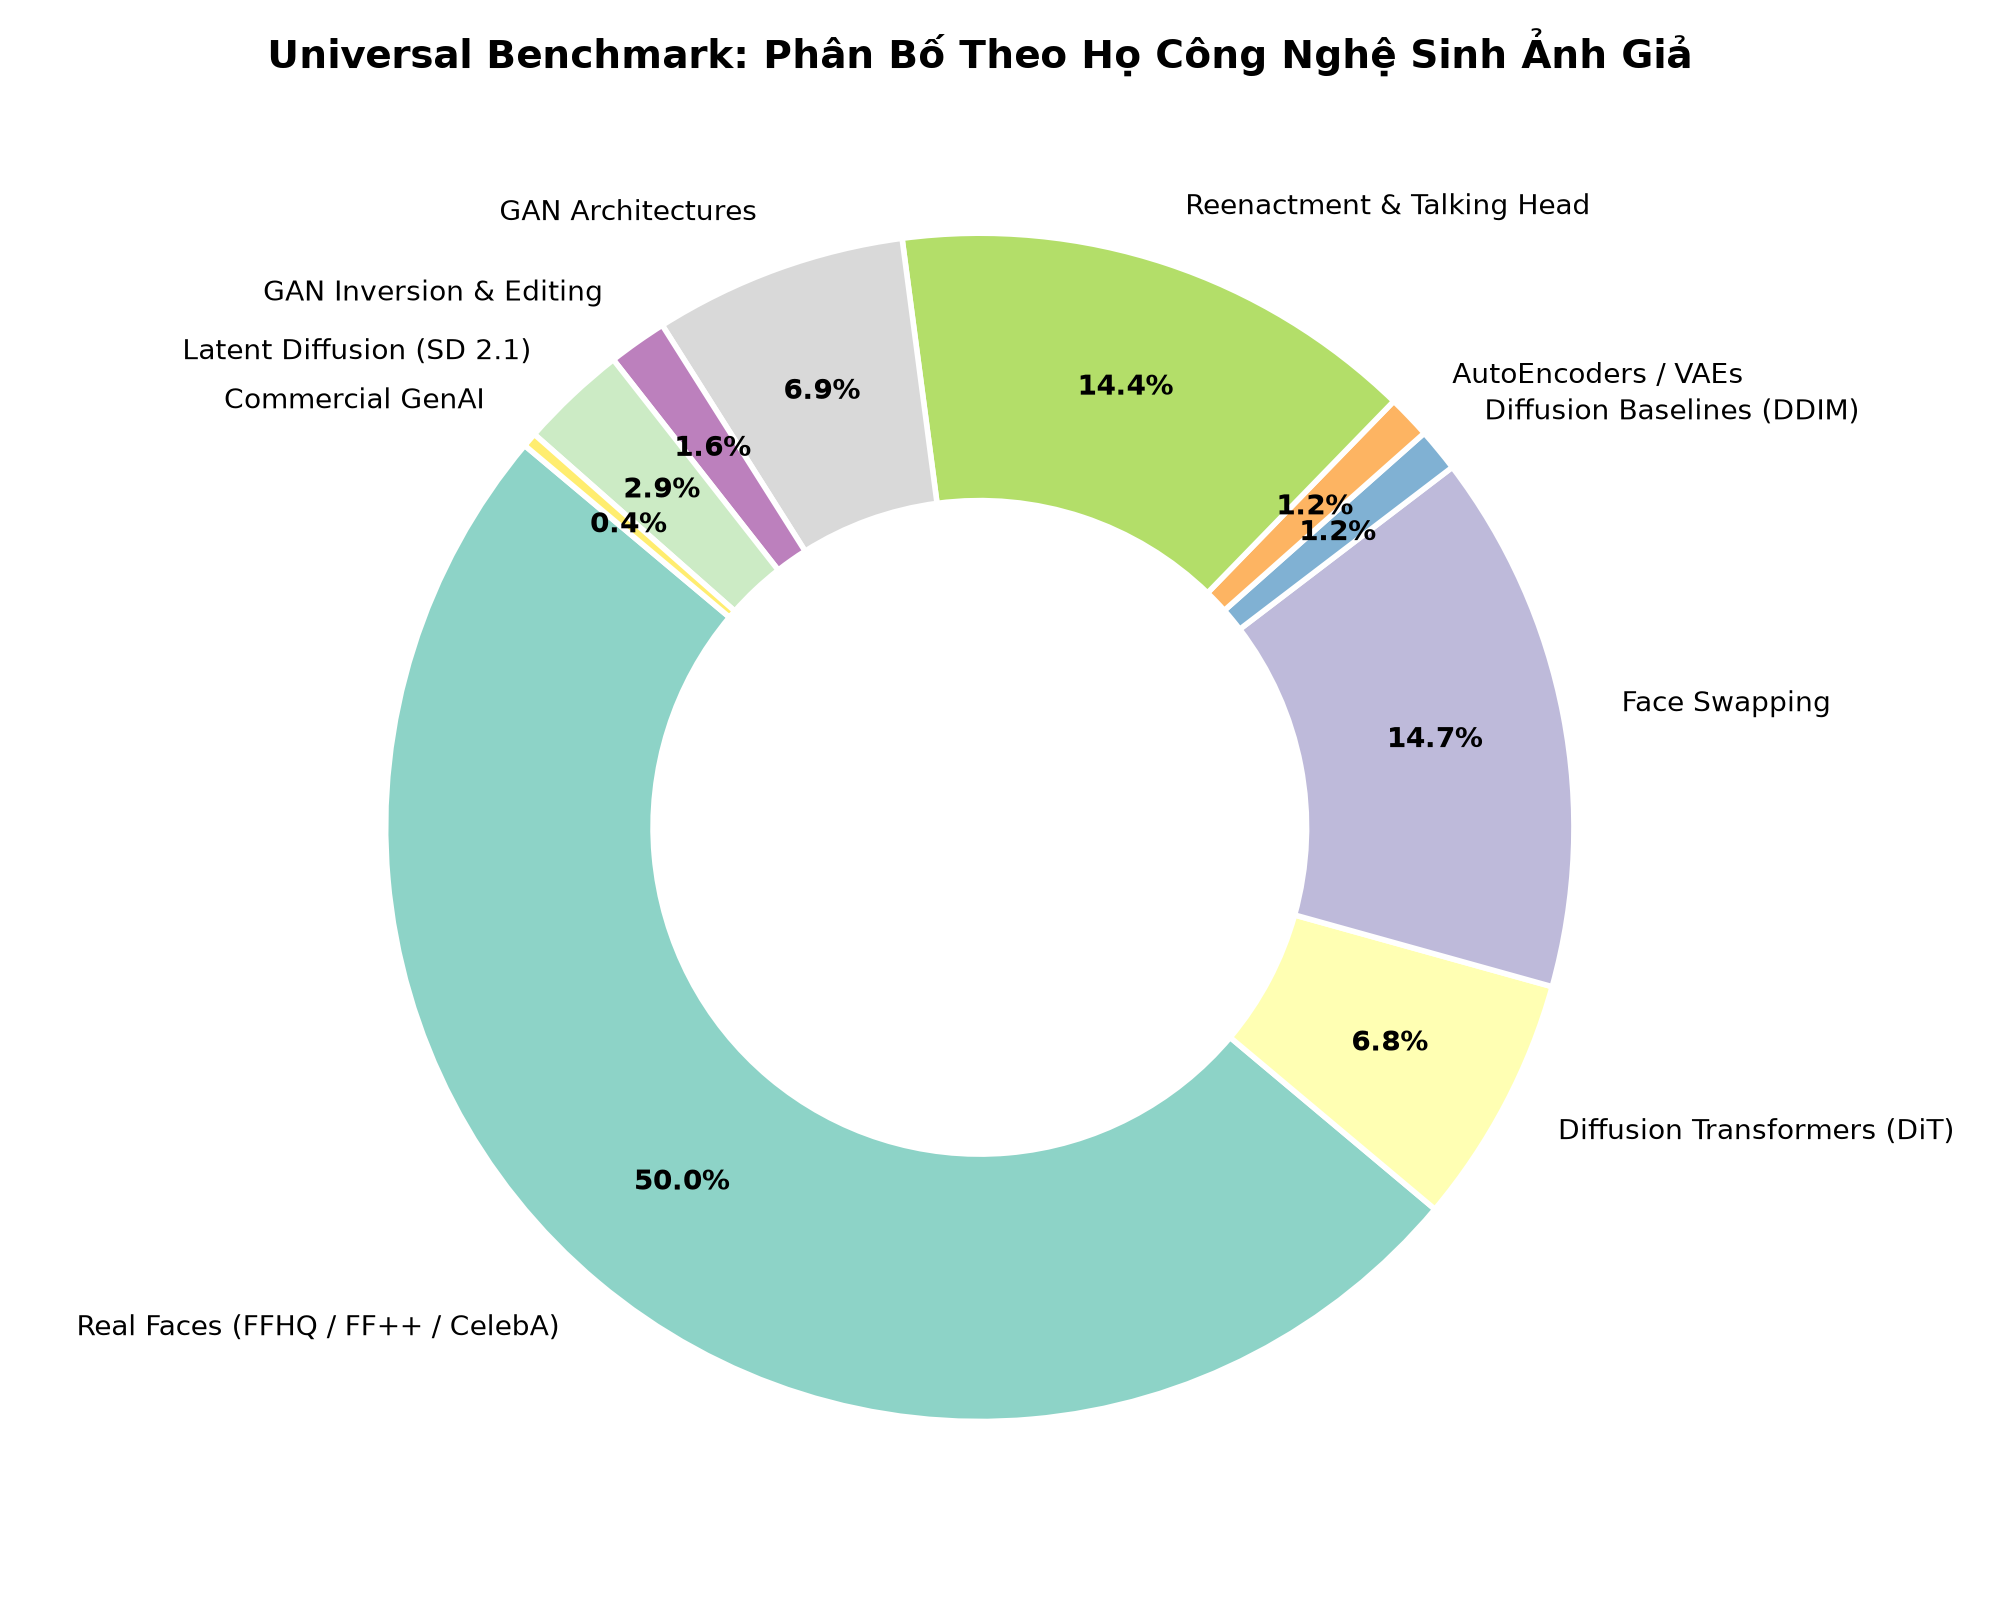

In [3]:
# --- [3. TRỰC QUAN HÓA PHÂN BỐ HỌ CÔNG NGHỆ (DONUT CHART)] ---
from IPython.display import Image as IPImage, display
display(IPImage(filename="experiments/eda/figures/universal_method_families.png"))


### 4. Xếp Hạng & Phân Bố Số Lượng 38 Phương Pháp Deepfake

Biểu đồ cột thể hiện phân bố mẫu thực tế của từng phương pháp tạo ảnh giả trong bộ kiểm định:


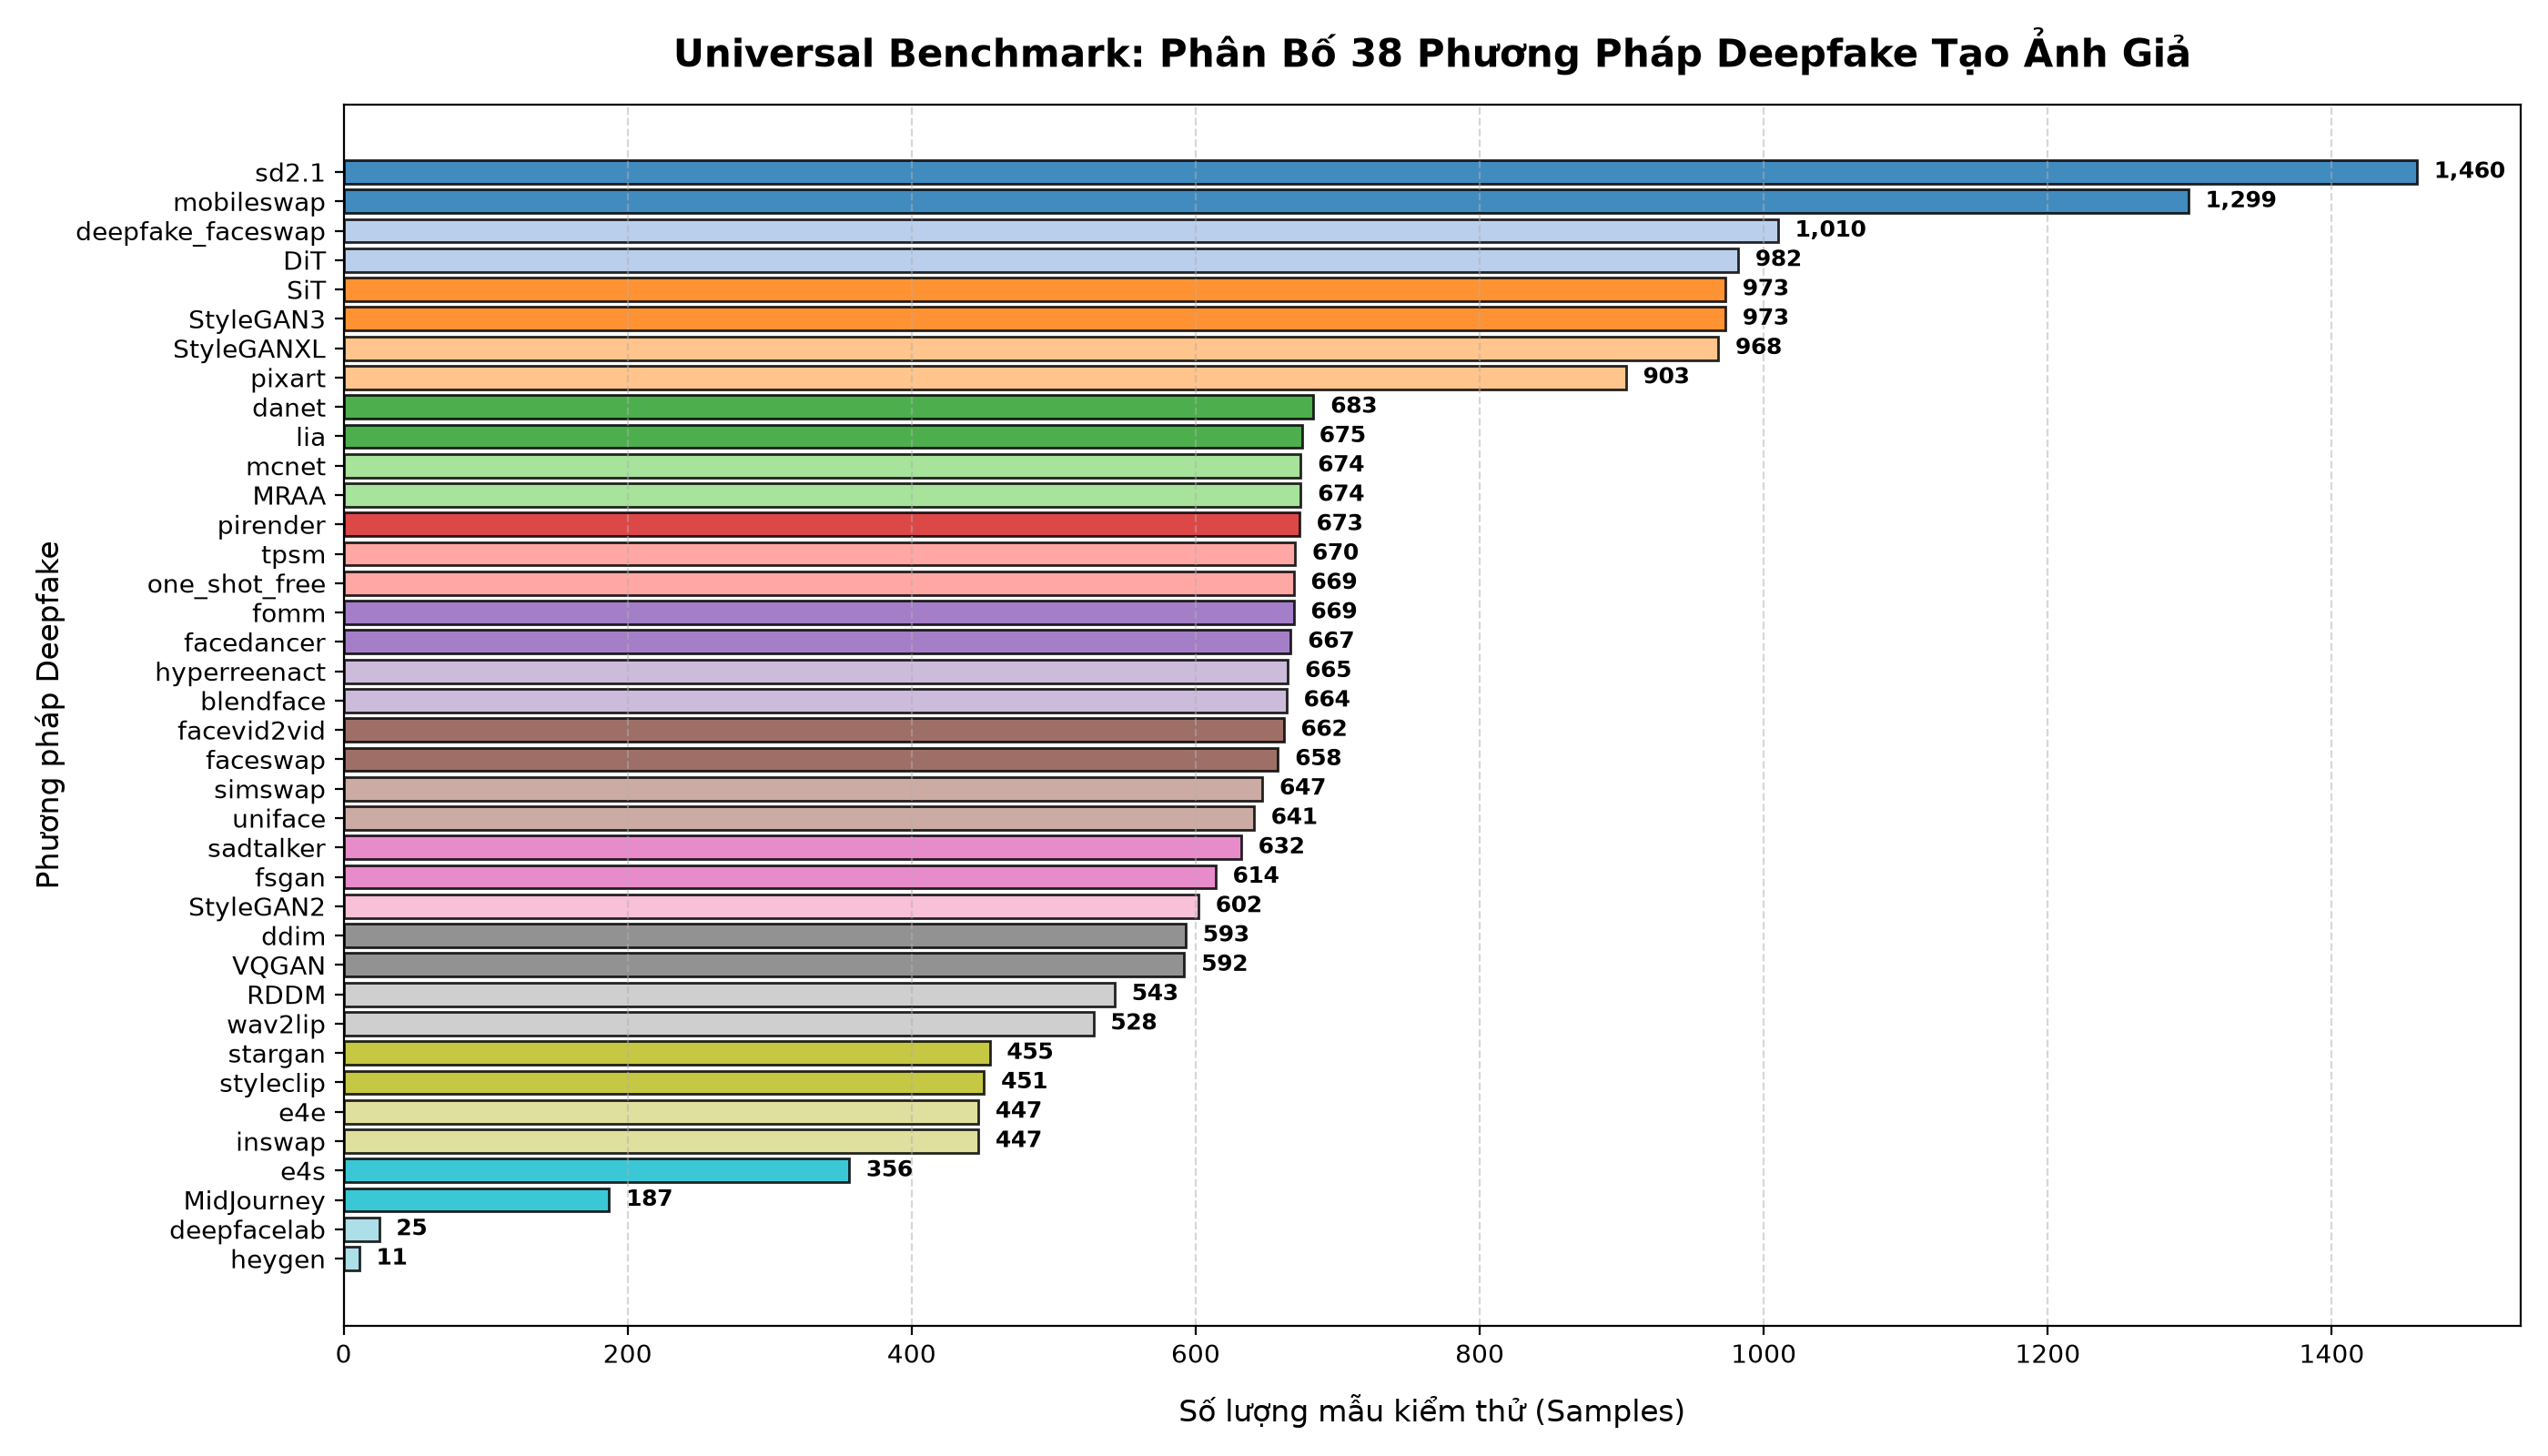

In [4]:
# --- [4. BIỂU ĐỒ PHÂN BỐ 38 PHƯƠNG PHÁP DEEPFAKE] ---
display(IPImage(filename="experiments/eda/figures/universal_method_distribution.png"))


### 5. Kiểm Toán Chất Lượng Quang Học (Laplacian Sharpness & Contrast)

Đo lường độ sắc nét qua **Phương sai toán tử Laplacian (Laplacian Variance $\sigma^2$)** trên kênh xám và độ tương phản RMS:
$$\text{Sharpness} = \text{Var}\left(\nabla^2 I_{\text{gray}}\right)$$

- **Hiện tượng Boundary Feathering**: Các phương pháp Face Swapping (`faceswap`: 42.3, `mobileswap`: 53.9) và Reenactment (`fomm`: 22.0, `wav2lip`: 26.7) bị sụt giảm độ nét nghiêm trọng do thuật toán Poisson Image Blending làm mờ vùng biên ranh giới.
- **Hiện tượng Hyper-Sharpening**: Nhóm Commercial GenAI (`MidJourney`: 966.8) và `RDDM` (1.778.4) có độ nét nhân tạo cực cao do các bộ lọc hậu kỳ.


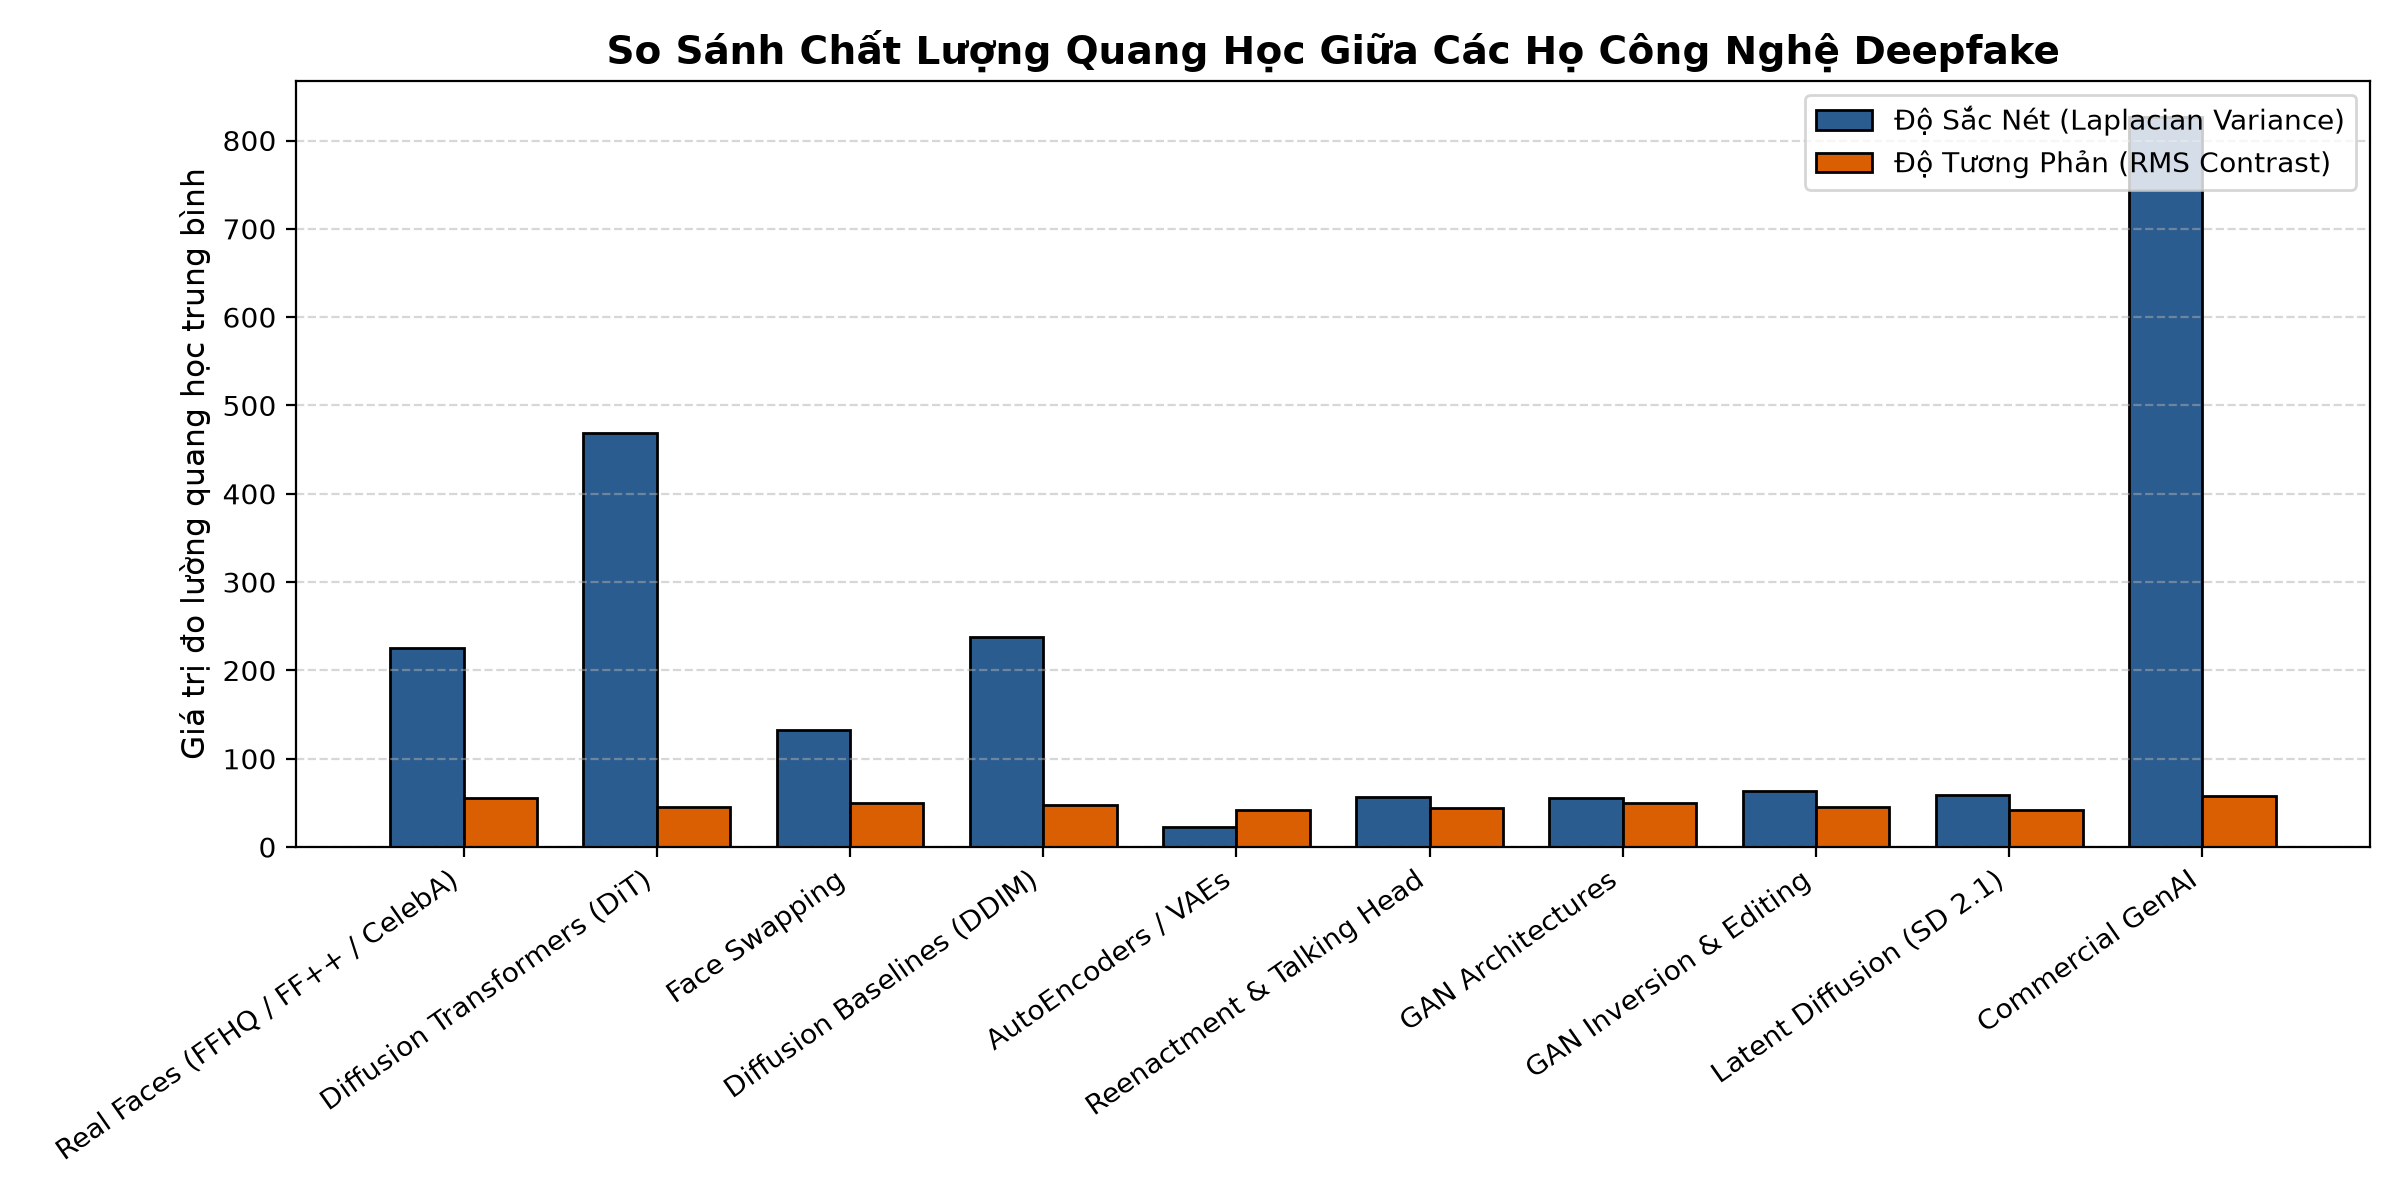

In [5]:
# --- [5. SO SÁNH CHẤT LƯỢNG QUANG HỌC GIỮA CÁC HỌ CÔNG NGHỆ] ---
display(IPImage(filename="experiments/eda/figures/universal_quality_by_family.png"))


### 6. Bộ Sưu Tập Ảnh Mẫu Đại Diện 12 Phương Pháp SOTA

Trực quan hóa trực tiếp các mẫu ảnh đại diện từ 12 nhóm phương pháp tiêu biểu:


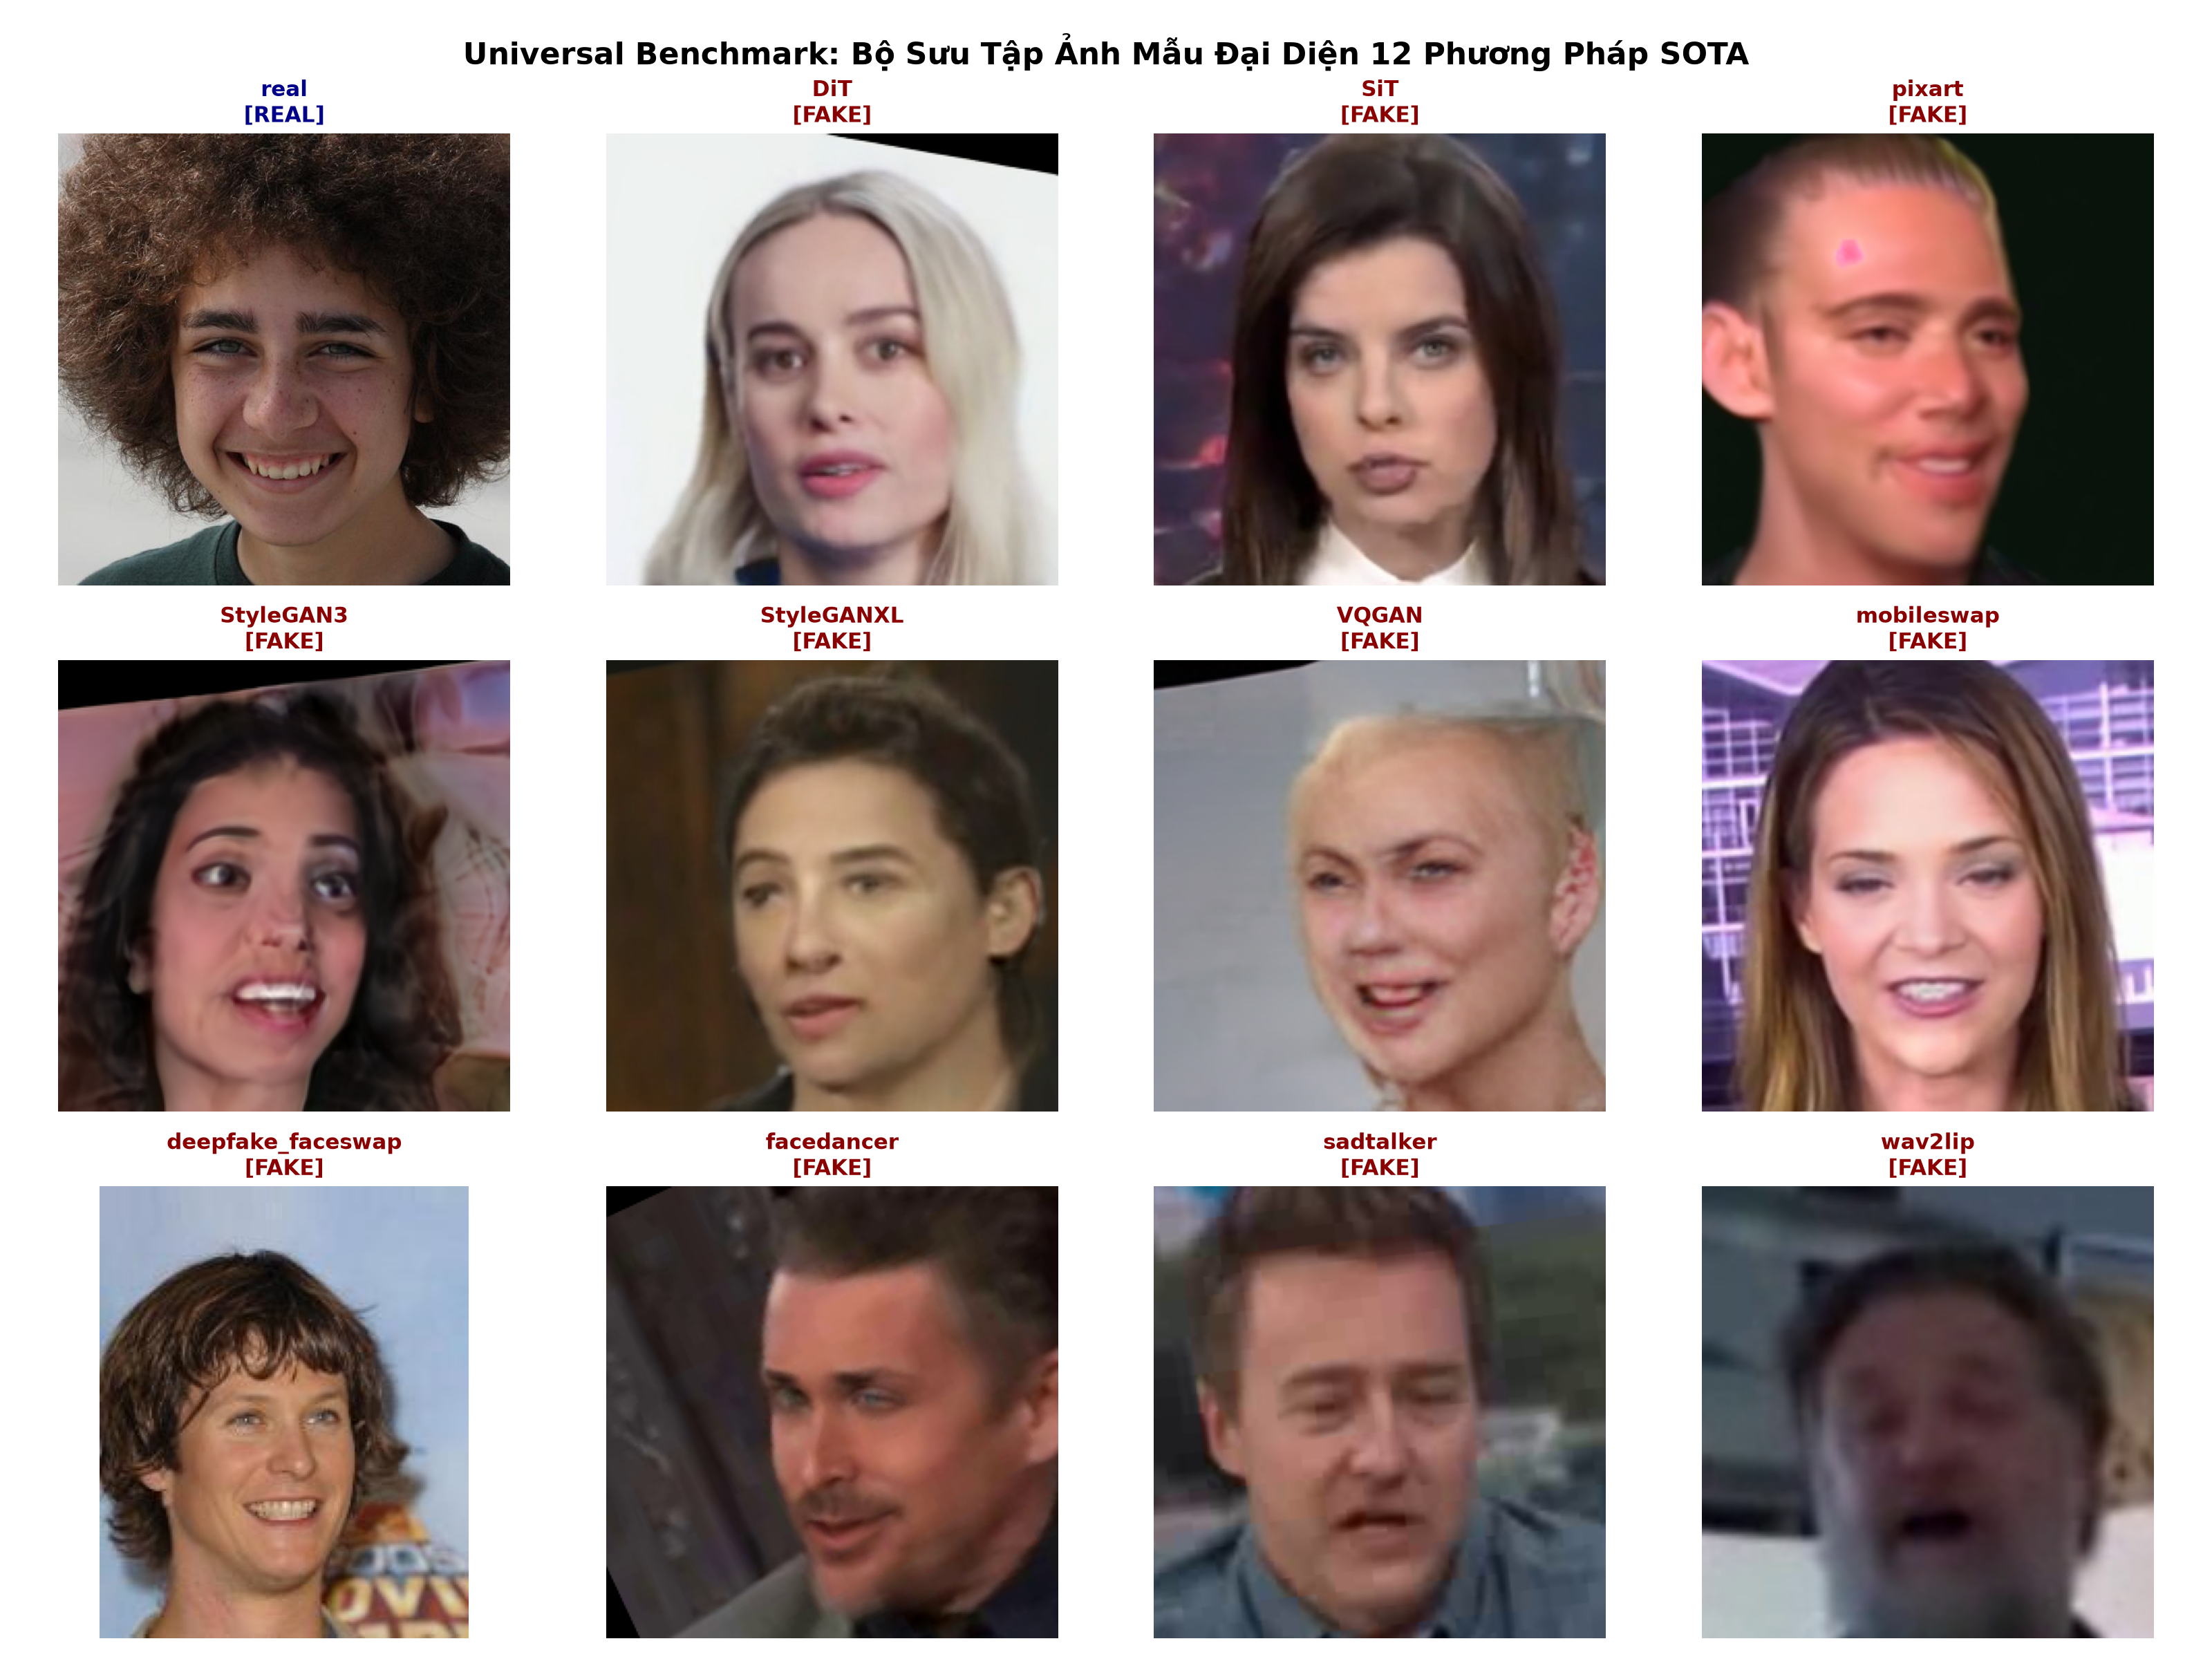

In [6]:
# --- [6. BỘ SƯU TẬP ẢNH MẪU ĐẠI DIỆN 12 PHƯƠNG PHÁP] ---
display(IPImage(filename="experiments/eda/figures/universal_representative_gallery.png"))


---
## 7. 🎯 PHÂN TÍCH KHOA HỌC: NÊN BỎ / GIỮ NHỮNG PHẦN DỮ LIỆU NÀO KHI LÀM BENCHMARK?

> **Câu hỏi cốt lõi**: Khi dùng bộ dữ liệu đa phương pháp này làm thước đo kiểm định benchmark cho các mô hình ($M_0, M_1, M_2^*$), ta nên loại bỏ hoặc chọn lọc những thành phần nào để đảm bảo tính **chuẩn xác, công bằng và có ý nghĩa thống kê cao nhất**?

Dưới đây là 4 khuyến nghị lọc dữ liệu dựa trên kết quả kiểm toán quang học và phân bố:

### ❌ NHÓM 1: CÁC PHƯƠNG PHÁP QUÁ ÍT MẪU (UNDER-SAMPLED ANOMALIES) — ĐÃ LOẠI BỎ KHỎI TẬP VÀNG
1. **`heygen` (Chỉ có 11 mẫu)**:
   - **Vấn đề**: $N=11$ là kích thước mẫu quá nhỏ, vi phạm định lý giới hạn trung tâm ($N \ge 30$). Chỉ cần đoán sai 1 ảnh thì sai số nhảy vọt tới gần **10%**.
   - **Hành động**: Đã loại bỏ khỏi tập benchmark chuẩn hóa.
2. **`deepfacelab` (Chỉ có 25 mẫu)**:
   - **Vấn đề**: $N=25 < 30$, quá ít để đại diện cho kỹ thuật DeepFaceLab truyền thống. Phương sai quá lớn.
   - **Hành động**: Đã loại bỏ khỏi tập benchmark chuẩn hóa.
3. **`MidJourney` (Chỉ có 187 mẫu)**:
   - **Vấn đề**: Thiếu hụt 113 mẫu so với hạn mức chuẩn 300 mẫu của tập balanced.
   - **Hành động**: Đã loại bỏ để bảo toàn trọng số đồng đều $1/35$ cho mỗi phương pháp.

### ⚠️ NHÓM 2: DỊ THƯỜNG VỀ TỶ LỆ KHUNG HÌNH (NON-SQUARE RESOLUTION) — NÊN CENTER CROP
- **`deepfake_faceswap` (Kích thước $178 \times 218$)**:
  - **Vấn đề**: Toàn bộ hơn 95% bộ dữ liệu là ảnh vuông ($1:1$) chuẩn ($256\times 256$, $512\times 512$, $1024\times 1024$). Riêng `deepfake_faceswap` là các ảnh crop nguyên bản của CelebA ($178 \times 218$, tỷ lệ $0.82$).
  - **Nguy cơ**: Khi đưa vào mô hình DINOv2 / ViT ($224 \times 224$), việc resize trực tiếp ảnh $178 \times 218$ sẽ làm **méo tỷ lệ khuôn mặt (mặt bị bè ngang 18%)**.
  - **Hành động**: Cần **Center Crop thành hình vuông $178 \times 178$ trước khi resize**.

### 🏆 CẤU HÌNH BENCHMARK VÀNG CHÍNH THỨC (GOLDEN 21K SUITE)

$$\text{Tổng số mẫu} = \underbrace{35 \text{ phương pháp} \times 300 \text{ ảnh}}_{\mathbf{10.500 \text{ ảnh Fake}}} + \underbrace{10.500 \text{ ảnh Real đối chứng}}_{\mathbf{10.500 \text{ ảnh Real}}} = \mathbf{21.000 \text{ ảnh}}$$

| Đặc Tính | Chuẩn Hóa |
| :--- | :--- |
| **Tập Dữ Liệu** | `data/benchmarks/universal_deepfake_benchmark/splits/test_coursework_35methods_golden_balanced.csv` |
| **Tính Cân Bằng** | Đúng $50.00\%$ Thật vs $50.00\%$ Giả (10.500 Real vs 10.500 Fake) |
| **Trọng số đóng góp** | Mỗi phương pháp Fake chiếm chính xác $1/35 \approx 2.857\%$ điểm số |


In [7]:
# --- [8. XÁC THỰC BỘ BENCHMARK CHUẨN HÓA VÀNG (GOLDEN 21K SUITE)] ---
golden_fakes = [r for r in golden_rows if r['label'] == '1']
golden_reals = [r for r in golden_rows if r['label'] == '0']
golden_method_counts = Counter(r['method'] for r in golden_fakes)

print("=== BỘ BENCHMARK CHUẨN HÓA ĐỀ XUẤT (GOLDEN 21K BENCHMARK) ===")
print(f"[*] Đường dẫn file: {golden_csv}")
print(f"[*] Số phương pháp Fake hợp lệ: {len(golden_method_counts)} phương pháp")
print(f"[*] Số lượng mẫu mỗi phương pháp Fake: đúng {set(golden_method_counts.values()).pop()} mẫu/method")
print(f"[*] Tổng số ảnh Fake: {len(golden_fakes):,} ảnh")
print(f"[*] Tổng số ảnh Real đối chứng: {len(golden_reals):,} ảnh")
print(f"[*] TỔNG QUY MÔ BENCHMARK CHUẨN: {len(golden_rows):,} ảnh (Cân bằng tuyệt đối 50/50)")


=== BỘ BENCHMARK CHUẨN HÓA ĐỀ XUẤT (GOLDEN 21K BENCHMARK) ===
[*] Đường dẫn file: data/benchmarks/universal_deepfake_benchmark/splits/test_coursework_35methods_golden_balanced.csv
[*] Số phương pháp Fake hợp lệ: 35 phương pháp
[*] Số lượng mẫu mỗi phương pháp Fake: đúng 300 mẫu/method
[*] Tổng số ảnh Fake: 10,500 ảnh
[*] Tổng số ảnh Real đối chứng: 10,500 ảnh
[*] TỔNG QUY MÔ BENCHMARK CHUẨN: 21,000 ảnh (Cân bằng tuyệt đối 50/50)


### 9. Công Cụ Tương Tác: Khám Phá Mẫu Ảnh Bất Kỳ Theo Phương Pháp (Interactive Sample Inspector)

Sử dụng hàm dưới đây để hiển thị trực quan và đo lường quang học (Laplacian, kích thước, histogram) của bất kỳ phương pháp nào trong 35 phương pháp benchmark:


In [8]:
# --- [9. HÀM TƯƠNG TÁC: XEM ẢNH & ĐO LƯỜNG QUANG HỌC CHI TIẾT] ---
def inspect_method_sample(method_name: str = "DiT"):
    base_img_dir = Path("data/benchmarks/universal_deepfake_benchmark/test_images")
    samples = [r for r in golden_rows if r["method"] == method_name]
    if not samples:
        print(f"[!] Không tìm thấy mẫu cho phương pháp: {method_name}")
        return
    
    sample = samples[0]
    rel_path = sample["path"].lstrip("/")
    full_p = base_img_dir / rel_path
    
    if not full_p.exists():
        print(f"[!] File ảnh không tồn tại: {full_p}")
        return
    
    im = Image.open(full_p).convert("RGB")
    arr = np.array(im)
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))
    ax1.imshow(im)
    ax1.set_title(f"Phương pháp: {method_name}\nNhãn: {'FAKE (1)' if sample['label']=='1' else 'REAL (0)'}\nKích thước: {im.size}", fontsize=11, fontweight="bold")
    ax1.axis("off")
    
    ax2.hist(gray.ravel(), bins=50, color="#2b5c8f", alpha=0.75, edgecolor="black")
    ax2.set_title(f"Histogram Cường Độ Xám\nĐộ sắc nét (Laplacian Var): {lap_var:.1f}", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Pixel Value [0 - 255]")
    ax2.set_ylabel("Tần suất")
    ax2.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# Thử nghiệm xem mẫu phương pháp DiT
inspect_method_sample("DiT")


Đang hiển thị mẫu đại diện cho phương pháp DiT...
